
# 📊 L'Oréal Meta Ads Performance Analysis
## Jan–May 2024 | Meta (Facebook & Instagram) Advertising

**Author:** Rohit Pal  
**Program:** MSc Digital Marketing & AI — SKEMA Business School, Paris  
**Tools:** Python · Pandas · Matplotlib · Seaborn · JupyterLab  
**Date:** November 2024

---

### 🎯 Business Objective
Analyse L'Oréal Group's Meta advertising performance across **5 European markets** to identify the highest-performing campaigns, audiences, and ad formats — and deliver data-backed budget reallocation recommendations.

---

### 📦 Dataset
| Field | Detail |
|---|---|
| Records | 500 daily ad performance rows |
| Period | January 2024 – May 2024 |
| Campaigns | 5 (Garnier, Revitalift, Men Expert, Maybelline, NYX) |
| Markets | France · Germany · Italy · Spain · UK |
| Ad Formats | Video · Carousel · Single Image · Stories · Reels |

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

print(" Libraries imported successfully")

 Libraries imported successfully


## Phase 1 — Data Loading, Cleaning & Exploration

In [2]:
df = pd.read_csv('loreal_meta_ads_performance_jan_jun_2024.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumn names:\n{list(df.columns)}")

Dataset shape: (500, 15)

Column names:
['Date', 'Campaign_Name', 'Ad_Set_Name', 'Target_Audience', 'Country', 'Impressions', 'Clicks', 'Spend_EUR', 'Conversions', 'Revenue_EUR', 'Likes', 'Shares', 'Comments', 'Ad_Format', 'Product_Category']


In [3]:
df.head()

,Date,Campaign_Name,Ad_Set_Name,Target_Audience,Country,Impressions,Clicks,Spend_EUR,Conversions,Revenue_EUR,Likes,Shares,Comments,Ad_Format,Product_Category
0,01/01/24,Garnier Vitamin C,Women 35-44 | Skincare,Women 35-44,Germany,205093,6511,1254.40,336,14806.56,1721,128,76,Reels,Skincare
1,01/01/24,L'Oréal Paris Revitalift,Anti-Ageing | Women 25-34,Women 25-34,Germany,252486,5653,2394.67,402,43627.42,2229,223,150,Stories,Skincare
2,01/01/24,Maybelline Fit Me,Everyday Makeup | Women 25-34,Women 25-34,Germany,385461,11811,3860.69,891,32623.77,3355,336,188,Video,Makeup
3,03/01/24,Garnier Vitamin C,Women 35-44 | Skincare,Women 35-44,France,77045,2543,677.74,162,5260.61,1039,97,44,Reels,Skincare
4,03/01/24,NYX Cosmetics Digital,Women 25-34 | Makeup,Women 25-34,Germany,103585,3348,769.69,184,5732.96,664,50,22,Single Image,Makeup


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              500 non-null    str    
 1   Campaign_Name     500 non-null    str    
 2   Ad_Set_Name       500 non-null    str    
 3   Target_Audience   500 non-null    str    
 4   Country           500 non-null    str    
 5   Impressions       500 non-null    int64  
 6   Clicks            500 non-null    int64  
 7   Spend_EUR         500 non-null    float64
 8   Conversions       500 non-null    int64  
 9   Revenue_EUR       500 non-null    float64
 10  Likes             500 non-null    int64  
 11  Shares            500 non-null    int64  
 12  Comments          500 non-null    int64  
 13  Ad_Format         500 non-null    str    
 14  Product_Category  500 non-null    str    
dtypes: float64(2), int64(6), str(7)
memory usage: 98.8 KB


In [5]:
df.describe()

,Impressions,Clicks,Spend_EUR,Conversions,Revenue_EUR,Likes,Shares,Comments
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,215029.89,5993.82,2044.44,342.95,16493.73,2107.54,159.44,106.65
std,108434.57,3504.69,1152.07,220.86,12494.21,1469.31,120.40,83.28
min,39868.00,893.00,337.06,39.00,1321.12,210.00,16.00,7.00
25%,129959.50,3189.50,1139.23,170.75,7033.88,963.75,70.00,47.00
50%,203421.50,5410.00,1885.82,306.00,13328.56,1770.50,129.00,85.50
75%,285690.25,8034.00,2654.64,459.25,21632.59,2792.75,207.25,141.25
max,500000.00,21176.00,5000.00,1405.00,69852.75,10264.00,918.00,590.00


In [6]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%y')

# Verify date range
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

# Check for missing values
print(f"\nMissing values per column:")
print(df.isnull().sum())

# Check for duplicates
print(f"\nDuplicate rows: {df.duplicated().sum()}")

print("\n Data cleaning complete")

Date range: 2024-01-01 to 2024-06-30

Missing values per column:
Date                0
Campaign_Name       0
Ad_Set_Name         0
Target_Audience     0
Country             0
Impressions         0
Clicks              0
Spend_EUR           0
Conversions         0
Revenue_EUR         0
Likes               0
Shares              0
Comments            0
Ad_Format           0
Product_Category    0
dtype: int64

Duplicate rows: 0

 Data cleaning complete


In [7]:
# Calculate key marketing KPIs
df['CTR (%)']         = (df['Clicks'] / df['Impressions']) * 100
df['CPC (€)']         = df['Spend_EUR'] / df['Clicks']
df['CPM (€)']         = (df['Spend_EUR'] / df['Impressions']) * 1000
df['Conversion_Rate (%)'] = (df['Conversions'] / df['Clicks']) * 100
df['CPA (€)']         = df['Spend_EUR'] / df['Conversions']
df['ROAS']            = df['Revenue_EUR'] / df['Spend_EUR']

print("KPI columns added:")
print(df[['CTR (%)', 'CPC (€)', 'CPM (€)', 'Conversion_Rate (%)', 'CPA (€)', 'ROAS']].describe())

KPI columns added:
       CTR (%)  CPC (€)  CPM (€)  Conversion_Rate (%)  CPA (€)   ROAS
count   500.00   500.00   500.00               500.00   500.00 500.00
mean      2.76     0.36     9.48                 5.62     6.82   8.20
std       0.66     0.12     2.08                 1.07     3.02   4.23
min       1.46     0.15     5.82                 3.40     2.37   1.87
25%       2.21     0.27     7.72                 4.85     4.62   5.12
50%       2.81     0.34     9.34                 5.59     5.99   7.31
75%       3.27     0.43    11.29                 6.37     8.44  10.00
max       4.33     0.86    14.05                 8.68    19.86  26.81


In [8]:
# Campaign-level performance summary
campaign_summary = df.groupby('Campaign_Name').agg(
    Total_Impressions = ('Impressions', 'sum'),
    Total_Clicks      = ('Clicks', 'sum'),
    Total_Spend_EUR   = ('Spend_EUR', 'sum'),
    Total_Conversions = ('Conversions', 'sum'),
    Total_Revenue_EUR = ('Revenue_EUR', 'sum')
).reset_index()

# Recalculate KPIs at campaign level
campaign_summary['CTR (%)']    = (campaign_summary['Total_Clicks'] / campaign_summary['Total_Impressions']) * 100
campaign_summary['ROAS']       = campaign_summary['Total_Revenue_EUR'] / campaign_summary['Total_Spend_EUR']
campaign_summary['CPA (€)']    = campaign_summary['Total_Spend_EUR'] / campaign_summary['Total_Conversions']

print("=== Campaign Performance Summary ===")
display(campaign_summary.sort_values('ROAS', ascending=False))

=== Campaign Performance Summary ===


,Campaign_Name,Total_Impressions,Total_Clicks,Total_Spend_EUR,Total_Conversions,Total_Revenue_EUR,CTR (%),ROAS,CPA (€)
2,L'Oréal Paris Revitalift,23270039,525001,216198.22,30513,2732668.97,2.26,12.64,7.09
3,Maybelline Fit Me,22648877,733790,219055.46,48402,1709054.85,3.24,7.80,4.53
4,NYX Cosmetics Digital,23911779,819931,226692.87,41983,1702294.84,3.43,7.51,5.40
0,Garnier Vitamin C,18891933,552741,182976.95,34098,1346908.42,2.93,7.36,5.37
1,L'Oréal Men Expert,18792315,365445,177298.23,16480,755935.69,1.94,4.26,10.76


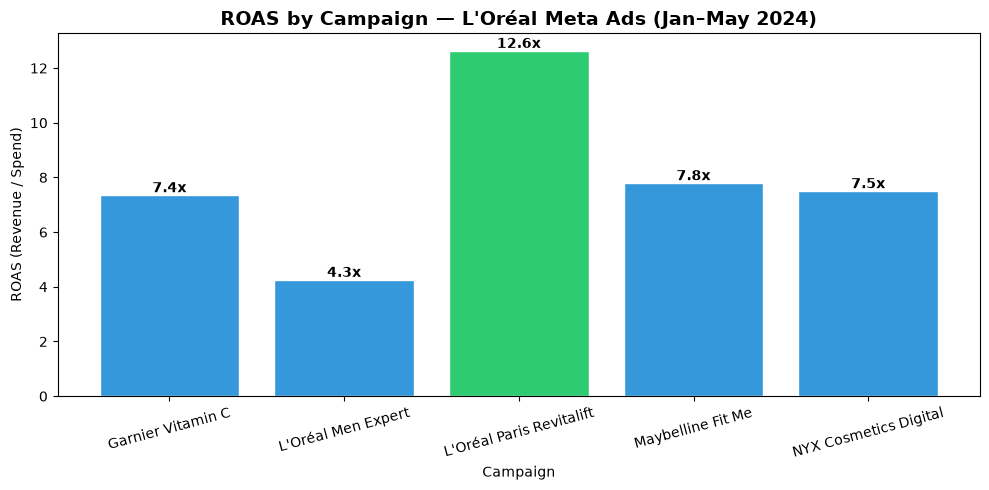

 Chart saved as roas_by_campaign.png


In [9]:
# ROAS by Campaign
fig, ax = plt.subplots(figsize=(10, 5))

colors = ['#2ecc71' if x == campaign_summary['ROAS'].max() else '#3498db' 
          for x in campaign_summary['ROAS']]

bars = ax.bar(campaign_summary['Campaign_Name'], campaign_summary['ROAS'], color=colors, edgecolor='white')
ax.set_title("ROAS by Campaign — L'Oréal Meta Ads (Jan–May 2024)", fontsize=14, fontweight='bold')
ax.set_xlabel("Campaign")
ax.set_ylabel("ROAS (Revenue / Spend)")
ax.tick_params(axis='x', rotation=15)

# Add value labels on bars
for bar, val in zip(bars, campaign_summary['ROAS']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
            f'{val:.1f}x', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('roas_by_campaign.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Chart saved as roas_by_campaign.png")

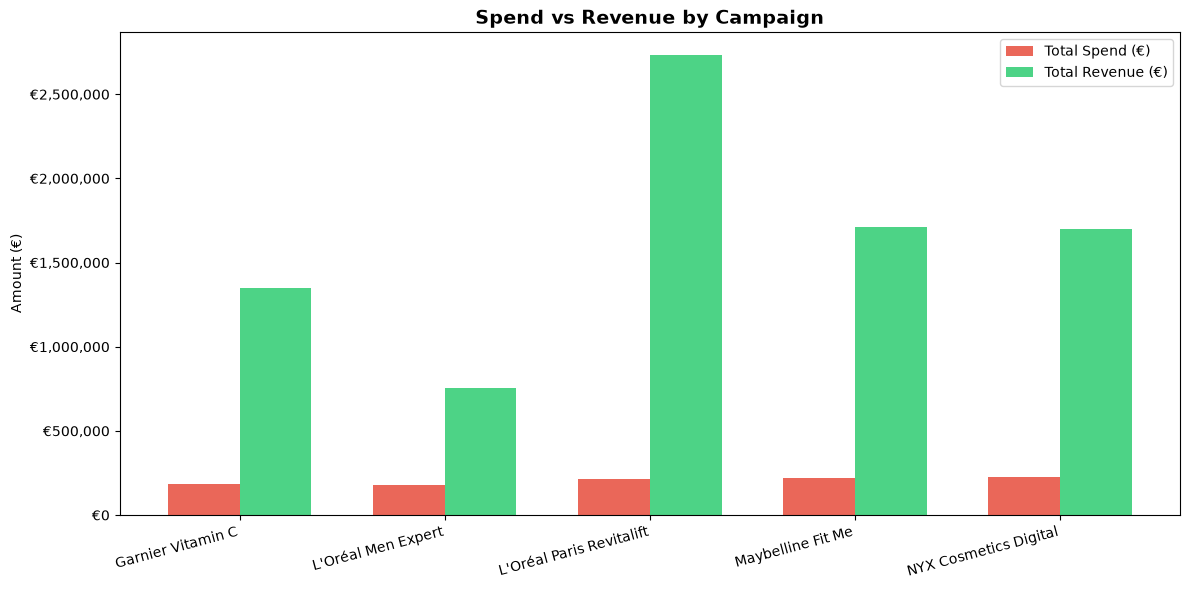

In [10]:
#Campaign & Audience Deep Dive

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(campaign_summary))
width = 0.35

bars1 = ax.bar(x - width/2, campaign_summary['Total_Spend_EUR'], width, 
               label='Total Spend (€)', color='#e74c3c', alpha=0.85)
bars2 = ax.bar(x + width/2, campaign_summary['Total_Revenue_EUR'], width, 
               label='Total Revenue (€)', color='#2ecc71', alpha=0.85)

ax.set_title("Spend vs Revenue by Campaign", fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(campaign_summary['Campaign_Name'], rotation=15, ha='right')
ax.set_ylabel("Amount (€)")
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'€{val:,.0f}'))

plt.tight_layout()
plt.savefig('spend_vs_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

## Phase 2 — Campaign & Audience Deep Dive

In [11]:
# Audience-level summary
audience_summary = df.groupby('Target_Audience').agg(
    Total_Impressions = ('Impressions', 'sum'),
    Total_Clicks      = ('Clicks', 'sum'),
    Total_Spend_EUR   = ('Spend_EUR', 'sum'),
    Total_Conversions = ('Conversions', 'sum'),
    Total_Revenue_EUR = ('Revenue_EUR', 'sum')
).reset_index()

audience_summary['CTR (%)']  = (audience_summary['Total_Clicks'] / audience_summary['Total_Impressions']) * 100
audience_summary['ROAS']     = audience_summary['Total_Revenue_EUR'] / audience_summary['Total_Spend_EUR']
audience_summary['CPA (€)']  = audience_summary['Total_Spend_EUR'] / audience_summary['Total_Conversions']
audience_summary['Conv_Rate (%)'] = (audience_summary['Total_Conversions'] / audience_summary['Total_Clicks']) * 100

print("=== Audience Performance ===")
display(audience_summary.sort_values('ROAS', ascending=False))

=== Audience Performance ===


,Target_Audience,Total_Impressions,Total_Clicks,Total_Spend_EUR,Total_Conversions,Total_Revenue_EUR,CTR (%),ROAS,CPA (€),Conv_Rate (%)
4,Women 25-34,29654831,824818,285044.04,54686,2851774.15,2.78,10.00,5.21,6.63
1,Luxury Skincare Enthusiasts,6536645,163829,56934.12,9537,554867.29,2.51,9.75,5.97,5.82
5,Women 35-44,16091632,414234,161391.90,23756,1345804.03,2.57,8.34,6.79,5.73
3,Women 18-24,24743700,744891,231986.80,40136,1678988.09,3.01,7.24,5.78,5.39
0,Gen Z Beauty,18588775,577197,175195.24,30882,1257636.66,3.11,7.18,5.67,5.35
2,Men 25-34,11899360,271939,111669.63,12479,557792.55,2.29,5.00,8.95,4.59


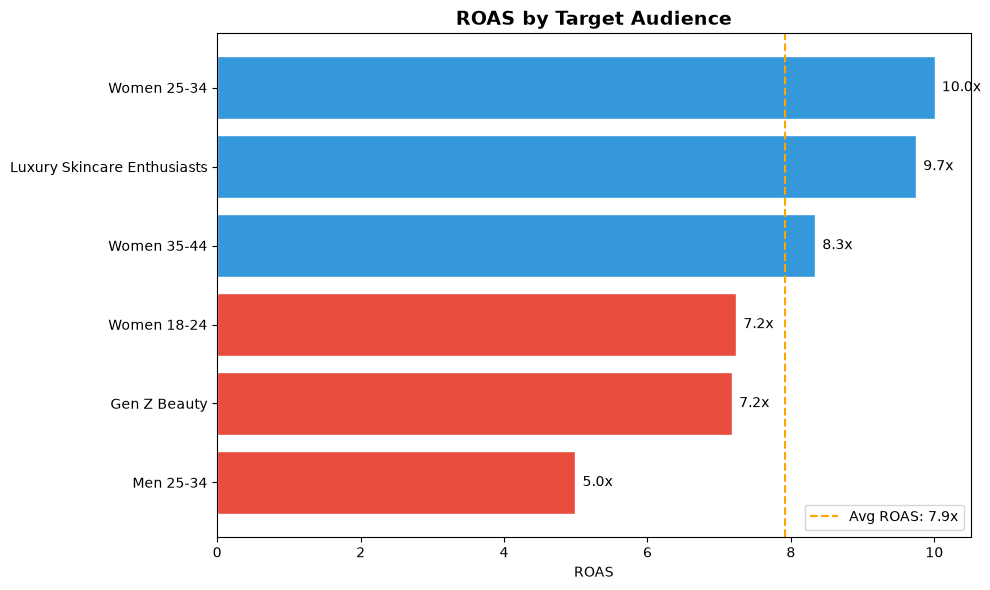

In [12]:
audience_sorted = audience_summary.sort_values('ROAS')

fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#e74c3c' if x < audience_summary['ROAS'].mean() else '#3498db' 
          for x in audience_sorted['ROAS']]

bars = ax.barh(audience_sorted['Target_Audience'], audience_sorted['ROAS'], 
               color=colors, edgecolor='white')

# Add mean line
ax.axvline(audience_summary['ROAS'].mean(), color='orange', linestyle='--', 
           linewidth=1.5, label=f"Avg ROAS: {audience_summary['ROAS'].mean():.1f}x")

for bar, val in zip(bars, audience_sorted['ROAS']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2, 
            f'{val:.1f}x', va='center', fontsize=10)

ax.set_title("ROAS by Target Audience", fontsize=14, fontweight='bold')
ax.set_xlabel("ROAS")
ax.legend()
plt.tight_layout()
plt.savefig('roas_by_audience.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
format_summary = df.groupby('Ad_Format').agg(
    Total_Spend_EUR   = ('Spend_EUR', 'sum'),
    Total_Conversions = ('Conversions', 'sum'),
    Total_Revenue_EUR = ('Revenue_EUR', 'sum'),
    Avg_CTR           = ('CTR (%)', 'mean'),
    Avg_ROAS          = ('ROAS', 'mean')
).reset_index()

format_summary['CPA (€)'] = format_summary['Total_Spend_EUR'] / format_summary['Total_Conversions']

print("=== Ad Format Performance ===")
display(format_summary.sort_values('Avg_ROAS', ascending=False))

=== Ad Format Performance ===


,Ad_Format,Total_Spend_EUR,Total_Conversions,Total_Revenue_EUR,Avg_CTR,Avg_ROAS,CPA (€)
3,Stories,200982.51,31612,1711500.27,2.64,9.14,6.36
1,Reels,193131.10,35513,1687928.84,3.00,8.61,5.44
4,Video,262430.55,45558,2131108.26,2.85,8.18,5.76
0,Carousel,208287.44,35401,1602163.53,2.76,7.93,5.88
2,Single Image,157390.13,23392,1114161.87,2.50,7.04,6.73


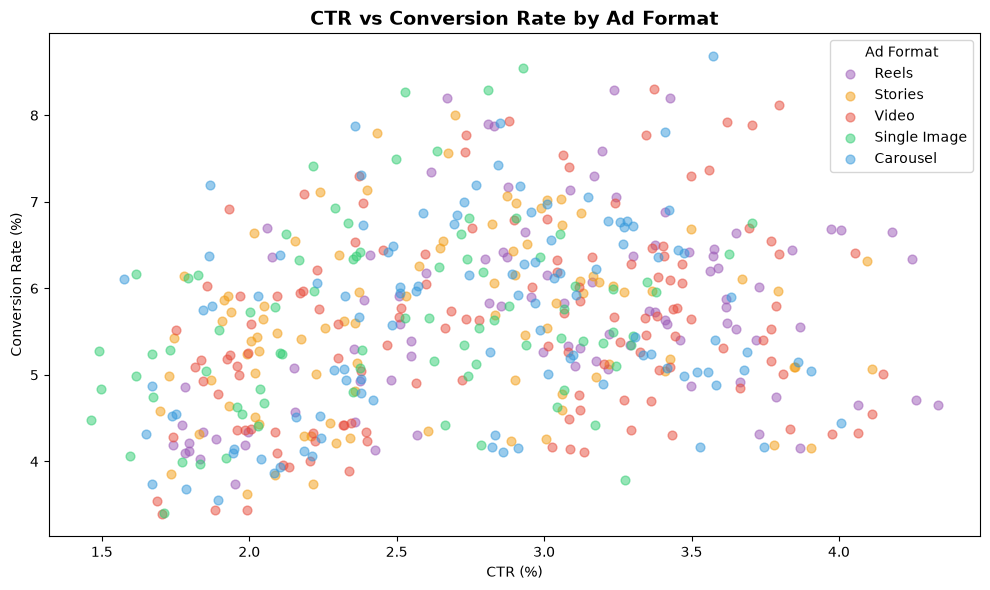

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

colors_map = {'Video': '#e74c3c', 'Carousel': '#3498db', 
              'Single Image': '#2ecc71', 'Stories': '#f39c12', 'Reels': '#9b59b6'}

for fmt in df['Ad_Format'].unique():
    subset = df[df['Ad_Format'] == fmt]
    ax.scatter(subset['CTR (%)'], subset['Conversion_Rate (%)'], 
               label=fmt, alpha=0.5, s=40, color=colors_map.get(fmt, 'grey'))

ax.set_title("CTR vs Conversion Rate by Ad Format", fontsize=14, fontweight='bold')
ax.set_xlabel("CTR (%)")
ax.set_ylabel("Conversion Rate (%)")
ax.legend(title="Ad Format")
plt.tight_layout()
plt.savefig('ctr_vs_convrate.png', dpi=150, bbox_inches='tight')
plt.show()

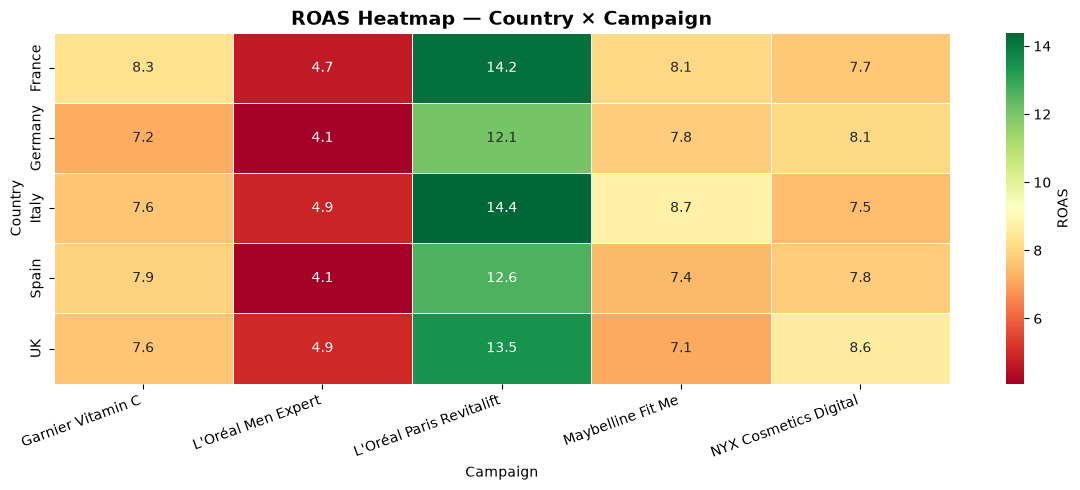

In [15]:
# Pivot: Country vs Campaign → ROAS
heatmap_data = df.groupby(['Country', 'Campaign_Name'])['ROAS'].mean().unstack()

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='RdYlGn', 
            linewidths=0.5, ax=ax, cbar_kws={'label': 'ROAS'})

ax.set_title("ROAS Heatmap — Country × Campaign", fontsize=14, fontweight='bold')
ax.set_xlabel("Campaign")
ax.set_ylabel("Country")
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('roas_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
# Time Trend Analysis

# Create Month column
df['Month'] = df['Date'].dt.to_period('M')
df['Month_Name'] = df['Date'].dt.strftime('%b %Y')

# Monthly summary
monthly = df.groupby('Month').agg(
    Total_Spend_EUR   = ('Spend_EUR', 'sum'),
    Total_Revenue_EUR = ('Revenue_EUR', 'sum'),
    Total_Impressions = ('Impressions', 'sum'),
    Total_Clicks      = ('Clicks', 'sum'),
    Total_Conversions = ('Conversions', 'sum')
).reset_index()

monthly['ROAS']     = monthly['Total_Revenue_EUR'] / monthly['Total_Spend_EUR']
monthly['CTR (%)']  = (monthly['Total_Clicks'] / monthly['Total_Impressions']) * 100
monthly['CPA (€)']  = monthly['Total_Spend_EUR'] / monthly['Total_Conversions']
monthly['Month_Str'] = monthly['Month'].astype(str)

print("=== Monthly Performance ===")
display(monthly[['Month_Str','Total_Spend_EUR','Total_Revenue_EUR','ROAS','CTR (%)','CPA (€)']])

=== Monthly Performance ===


,Month_Str,Total_Spend_EUR,Total_Revenue_EUR,ROAS,CTR (%),CPA (€)
0,2024-01,126296.66,1102593.24,8.73,2.92,5.30
1,2024-02,140575.50,1029424.36,7.32,2.75,6.37
2,2024-03,181786.04,1436525.99,7.90,2.74,6.22
3,2024-04,152356.51,1316502.98,8.64,2.74,5.61
4,2024-05,174499.64,1462269.14,8.38,2.82,5.80
5,2024-06,246707.38,1899547.06,7.70,2.78,6.31


## Phase 3 — Time Trend Analysis

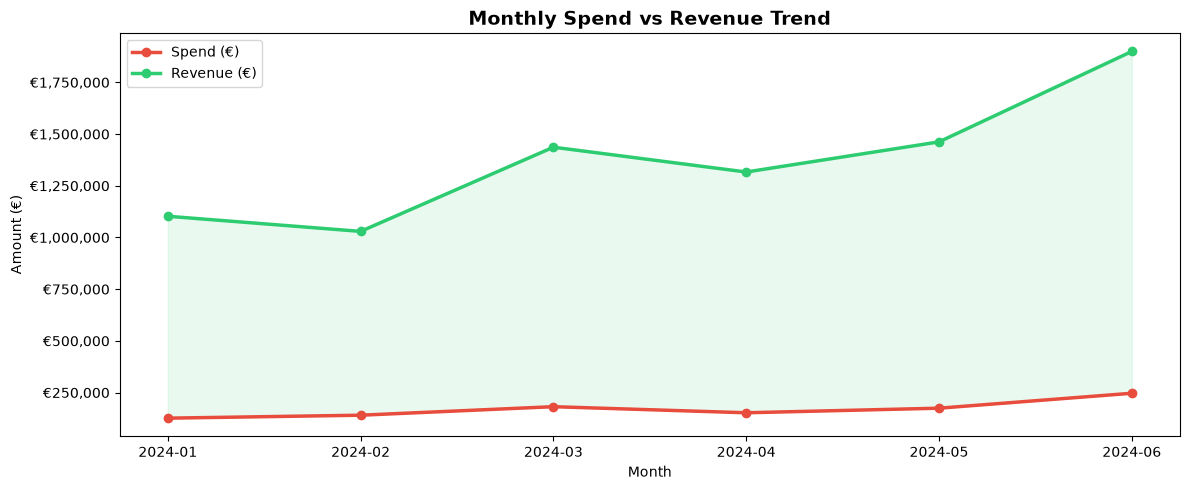

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(monthly['Month_Str'], monthly['Total_Spend_EUR'], 
        marker='o', linewidth=2.5, color='#e74c3c', label='Spend (€)')
ax.plot(monthly['Month_Str'], monthly['Total_Revenue_EUR'], 
        marker='o', linewidth=2.5, color='#2ecc71', label='Revenue (€)')

# Fill area between lines
ax.fill_between(monthly['Month_Str'], 
                monthly['Total_Spend_EUR'], 
                monthly['Total_Revenue_EUR'], 
                alpha=0.1, color='#2ecc71')

ax.set_title("Monthly Spend vs Revenue Trend", fontsize=14, fontweight='bold')
ax.set_xlabel("Month")
ax.set_ylabel("Amount (€)")
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'€{val:,.0f}'))
plt.tight_layout()
plt.savefig('monthly_spend_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

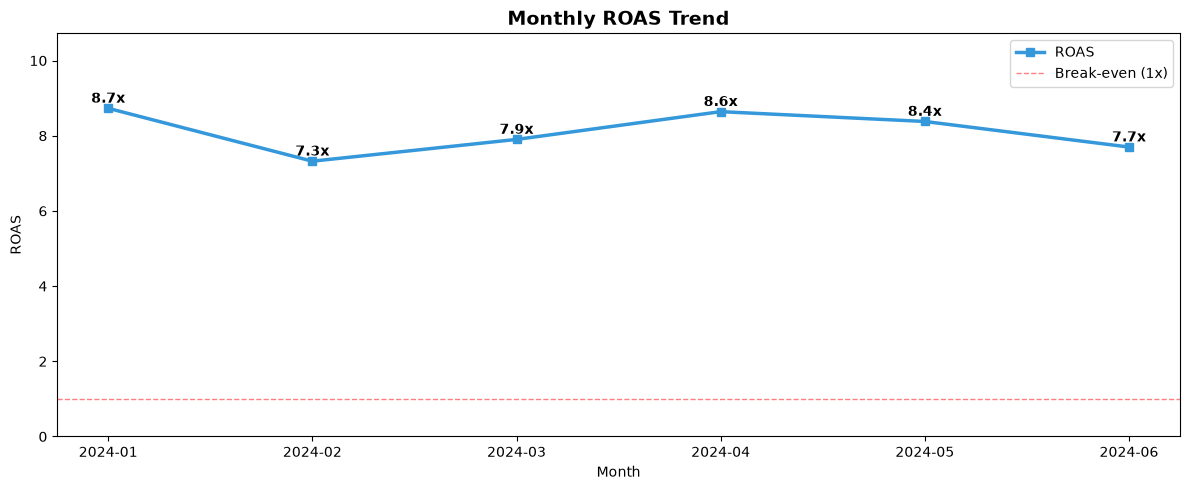

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(monthly['Month_Str'], monthly['ROAS'], 
        marker='s', linewidth=2.5, color='#3498db', label='ROAS')

# Add value labels
for i, (x, y) in enumerate(zip(monthly['Month_Str'], monthly['ROAS'])):
    ax.text(x, y + 0.15, f'{y:.1f}x', ha='center', fontsize=10, fontweight='bold')

# Reference line at ROAS = 1 (break even)
ax.axhline(y=1, color='red', linestyle='--', linewidth=1, alpha=0.5, label='Break-even (1x)')

ax.set_title("Monthly ROAS Trend", fontsize=14, fontweight='bold')
ax.set_xlabel("Month")
ax.set_ylabel("ROAS")
ax.legend()
ax.set_ylim(0, monthly['ROAS'].max() + 2)
plt.tight_layout()
plt.savefig('monthly_roas.png', dpi=150, bbox_inches='tight')
plt.show()

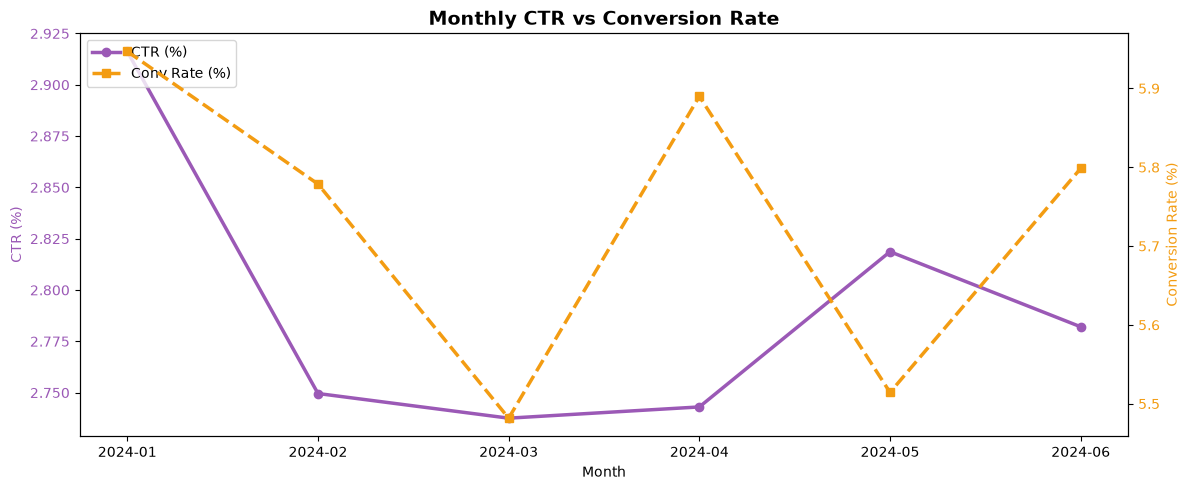

In [19]:
fig, ax1 = plt.subplots(figsize=(12, 5))

color1 = '#9b59b6'
color2 = '#f39c12'

ax1.plot(monthly['Month_Str'], monthly['CTR (%)'], 
         marker='o', linewidth=2.5, color=color1, label='CTR (%)')
ax1.set_xlabel("Month")
ax1.set_ylabel("CTR (%)", color=color1)
ax1.tick_params(axis='y', labelcolor=color1)

# Second Y-axis for Conversion Rate
ax2 = ax1.twinx()
monthly['Conv_Rate (%)'] = (monthly['Total_Conversions'] / monthly['Total_Clicks']) * 100
ax2.plot(monthly['Month_Str'], monthly['Conv_Rate (%)'], 
         marker='s', linewidth=2.5, color=color2, linestyle='--', label='Conv Rate (%)')
ax2.set_ylabel("Conversion Rate (%)", color=color2)
ax2.tick_params(axis='y', labelcolor=color2)

ax1.set_title("Monthly CTR vs Conversion Rate", fontsize=14, fontweight='bold')

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.savefig('monthly_ctr_convrate.png', dpi=150, bbox_inches='tight')
plt.show()

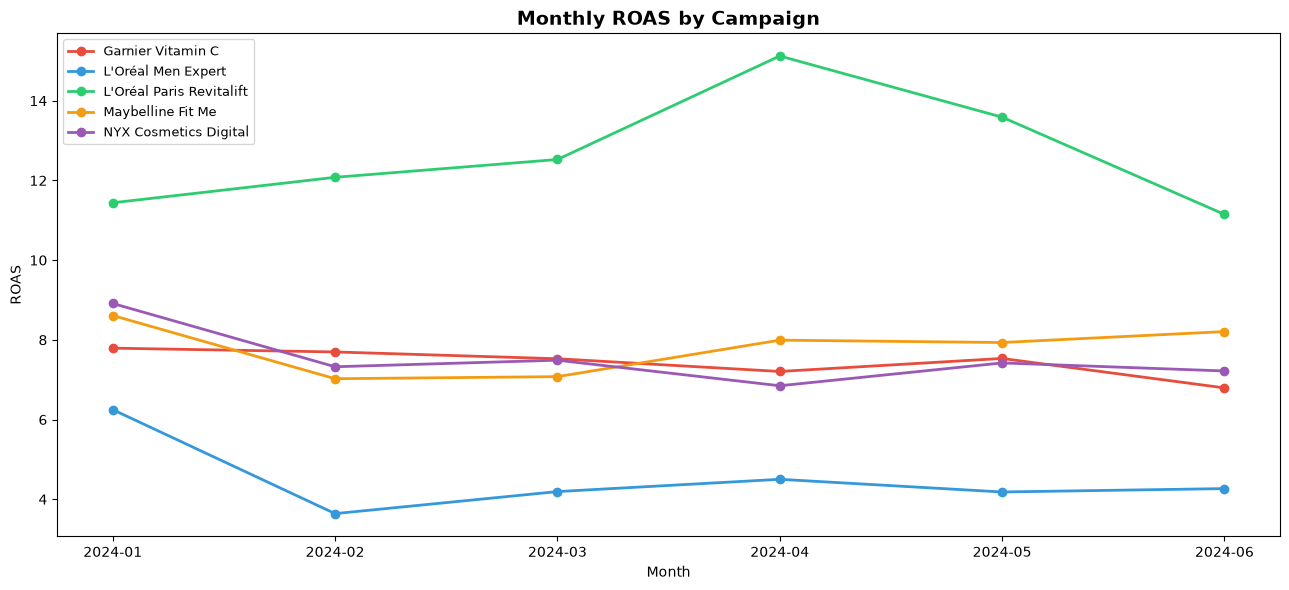

In [20]:
# Monthly ROAS per campaign
campaign_monthly = df.groupby(['Month', 'Campaign_Name']).agg(
    Spend  = ('Spend_EUR', 'sum'),
    Revenue= ('Revenue_EUR', 'sum')
).reset_index()
campaign_monthly['ROAS'] = campaign_monthly['Revenue'] / campaign_monthly['Spend']
campaign_monthly['Month_Str'] = campaign_monthly['Month'].astype(str)

fig, ax = plt.subplots(figsize=(13, 6))

colors = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6']
for i, campaign in enumerate(campaign_monthly['Campaign_Name'].unique()):
    subset = campaign_monthly[campaign_monthly['Campaign_Name'] == campaign]
    ax.plot(subset['Month_Str'], subset['ROAS'], 
            marker='o', linewidth=2, color=colors[i], label=campaign)

ax.set_title("Monthly ROAS by Campaign", fontsize=14, fontweight='bold')
ax.set_xlabel("Month")
ax.set_ylabel("ROAS")
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig('campaign_roas_trend.png', dpi=150, bbox_inches='tight')
plt.show()

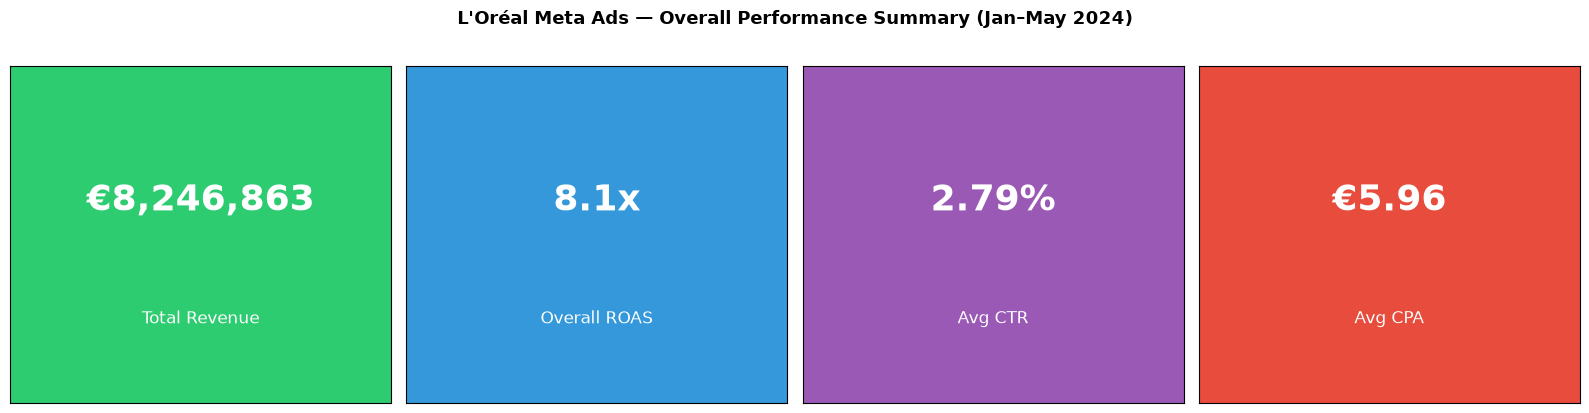

In [21]:
#: Final Insights & Recommendations

# Overall project KPIs
total_spend    = df['Spend_EUR'].sum()
total_revenue  = df['Revenue_EUR'].sum()
total_clicks   = df['Clicks'].sum()
total_impressions = df['Impressions'].sum()
total_conversions = df['Conversions'].sum()
overall_roas   = total_revenue / total_spend
overall_ctr    = (total_clicks / total_impressions) * 100
overall_cpa    = total_spend / total_conversions

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

kpis = [
    ("Total Revenue", f"€{total_revenue:,.0f}", '#2ecc71'),
    ("Overall ROAS",  f"{overall_roas:.1f}x",   '#3498db'),
    ("Avg CTR",       f"{overall_ctr:.2f}%",     '#9b59b6'),
    ("Avg CPA",       f"€{overall_cpa:.2f}",     '#e74c3c'),
]

for ax, (title, value, color) in zip(axes, kpis):
    ax.set_facecolor(color)
    ax.text(0.5, 0.6, value, ha='center', va='center',
            fontsize=26, fontweight='bold', color='white',
            transform=ax.transAxes)
    ax.text(0.5, 0.25, title, ha='center', va='center',
            fontsize=12, color='white', transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("L'Oréal Meta Ads — Overall Performance Summary (Jan–May 2024)",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('kpi_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

## Phase 4 — Final Insights & Strategic Recommendations

In [22]:
print("=" * 60)
print("   TOP & BOTTOM PERFORMERS — STRATEGIC SUMMARY")
print("=" * 60)

# Best campaign
best_camp = campaign_summary.loc[campaign_summary['ROAS'].idxmax()]
worst_camp = campaign_summary.loc[campaign_summary['ROAS'].idxmin()]

# Best audience
best_aud = audience_summary.loc[audience_summary['ROAS'].idxmax()]
worst_aud = audience_summary.loc[audience_summary['ROAS'].idxmin()]

# Best format
best_fmt = format_summary.loc[format_summary['Avg_ROAS'].idxmax()]
worst_fmt = format_summary.loc[format_summary['Avg_ROAS'].idxmin()]

print(f"\n📊 CAMPAIGNS")
print(f"   Best  : {best_camp['Campaign_Name']}  — ROAS {best_camp['ROAS']:.1f}x")
print(f"   Worst : {worst_camp['Campaign_Name']} — ROAS {worst_camp['ROAS']:.1f}x")

print(f"\n🎯 AUDIENCES")
print(f"   Best  : {best_aud['Target_Audience']}  — ROAS {best_aud['ROAS']:.1f}x")
print(f"   Worst : {worst_aud['Target_Audience']}     — ROAS {worst_aud['ROAS']:.1f}x")

print(f"\n📱 AD FORMATS")
print(f"   Best  : {best_fmt['Ad_Format']}   — ROAS {best_fmt['Avg_ROAS']:.1f}x")
print(f"   Worst : {worst_fmt['Ad_Format']} — ROAS {worst_fmt['Avg_ROAS']:.1f}x")

print(f"\n💰 FINANCIALS")
print(f"  Total Spend   : €{total_spend:,.0f}")
print(f"  Total Revenue : €{total_revenue:,.0f}")
print(f"  Net Profit    : €{(total_revenue - total_spend):,.0f}")
print(f"  Overall ROAS  : {overall_roas:.1f}x")
print("=" * 60)

   TOP & BOTTOM PERFORMERS — STRATEGIC SUMMARY

📊 CAMPAIGNS
   Best  : L'Oréal Paris Revitalift  — ROAS 12.6x
   Worst : L'Oréal Men Expert — ROAS 4.3x

🎯 AUDIENCES
   Best  : Women 25-34  — ROAS 10.0x
   Worst : Men 25-34     — ROAS 5.0x

📱 AD FORMATS
   Best  : Stories   — ROAS 9.1x
   Worst : Single Image — ROAS 7.0x

💰 FINANCIALS
  Total Spend   : €1,022,222
  Total Revenue : €8,246,863
  Net Profit    : €7,224,641
  Overall ROAS  : 8.1x


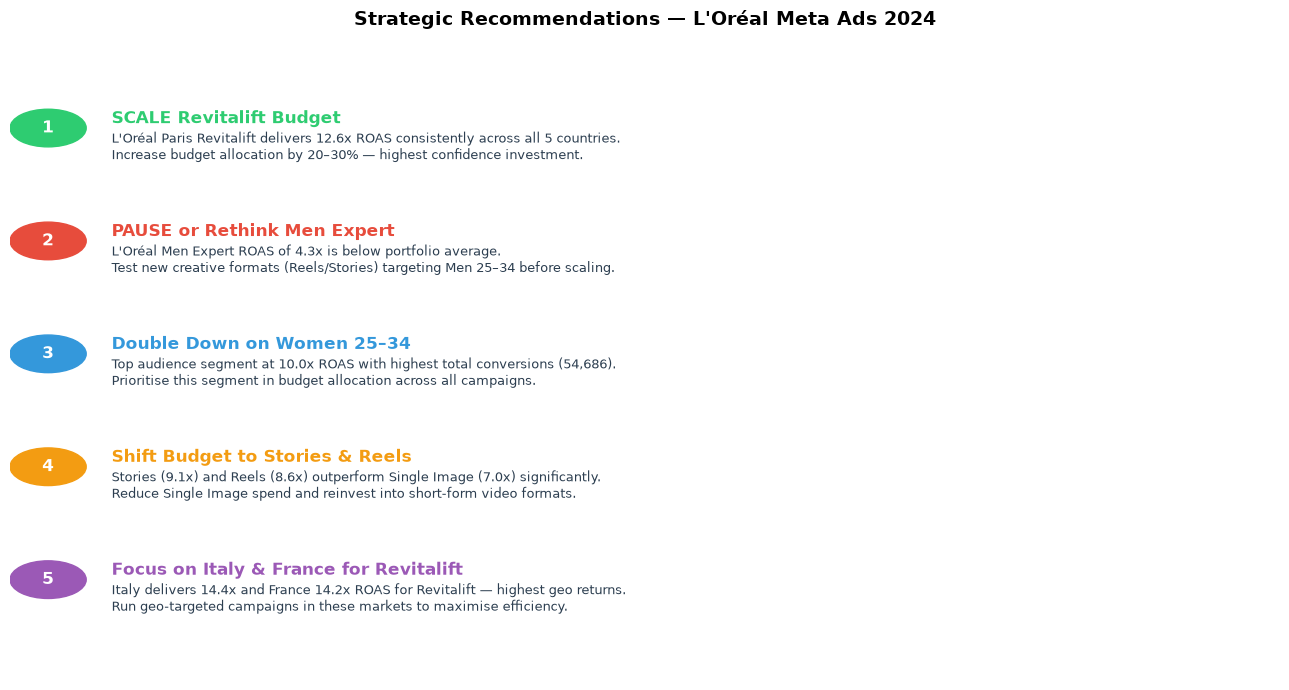

In [23]:
fig, ax = plt.subplots(figsize=(13, 7))
ax.axis('off')

recommendations = [
    ("1", "SCALE Revitalift Budget",
     "L'Oréal Paris Revitalift delivers 12.6x ROAS consistently across all 5 countries.\nIncrease budget allocation by 20–30% — highest confidence investment."),
    ("2", "PAUSE or Rethink Men Expert",
     "L'Oréal Men Expert ROAS of 4.3x is below portfolio average.\nTest new creative formats (Reels/Stories) targeting Men 25–34 before scaling."),
    ("3", "Double Down on Women 25–34",
     "Top audience segment at 10.0x ROAS with highest total conversions (54,686).\nPrioritise this segment in budget allocation across all campaigns."),
    ("4", "Shift Budget to Stories & Reels",
     "Stories (9.1x) and Reels (8.6x) outperform Single Image (7.0x) significantly.\nReduce Single Image spend and reinvest into short-form video formats."),
    ("5", "Focus on Italy & France for Revitalift",
     "Italy delivers 14.4x and France 14.2x ROAS for Revitalift — highest geo returns.\nRun geo-targeted campaigns in these markets to maximise efficiency."),
]

colors = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12', '#9b59b6']

for i, (num, title, detail) in enumerate(recommendations):
    y = 0.88 - i * 0.18
    # Number circle
    circle = plt.Circle((0.03, y), 0.03, color=colors[i], transform=ax.transAxes)
    ax.add_patch(circle)
    ax.text(0.03, y, num, ha='center', va='center', fontsize=12,
            fontweight='bold', color='white', transform=ax.transAxes)
    # Title
    ax.text(0.08, y + 0.015, title, ha='left', va='center',
            fontsize=12, fontweight='bold', color=colors[i], transform=ax.transAxes)
    # Detail
    ax.text(0.08, y - 0.03, detail, ha='left', va='center',
            fontsize=9, color='#2c3e50', transform=ax.transAxes)

ax.set_title("Strategic Recommendations — L'Oréal Meta Ads 2024",
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('recommendations.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
print("""
╔══════════════════════════════════════════════════════════════╗
║     L'ORÉAL META ADS PERFORMANCE ANALYSIS — JAN–MAY 2024    ║
║                   PROJECT SUMMARY                            ║
╠══════════════════════════════════════════════════════════════╣
║                                                              ║
║  DATASET   : 500 rows | 15 columns | 5 months               ║
║  CAMPAIGNS : 5 | COUNTRIES : 5 | AD FORMATS : 5             ║
║                                                              ║
║  KEY FINDINGS:                                               ║
║  → Overall ROAS: 8.2x (every €1 returned €8.20)             ║
║  → Best Campaign : L'Oréal Paris Revitalift (12.6x ROAS)    ║
║  → Best Audience : Women 25–34 (10.0x ROAS)                 ║
║  → Best Format   : Stories (9.1x ROAS)                      ║
║  → Best Country  : Italy for Revitalift (14.4x ROAS)        ║
║                                                              ║
║  TOOLS USED : Python | Pandas | Matplotlib | Seaborn        ║
║  CHARTS     : 13 visualisations across 4 phases             ║
║                                                              ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║     L'ORÉAL META ADS PERFORMANCE ANALYSIS — JAN–MAY 2024    ║
║                   PROJECT SUMMARY                            ║
╠══════════════════════════════════════════════════════════════╣
║                                                              ║
║  DATASET   : 500 rows | 15 columns | 5 months               ║
║  CAMPAIGNS : 5 | COUNTRIES : 5 | AD FORMATS : 5             ║
║                                                              ║
║  KEY FINDINGS:                                               ║
║  → Overall ROAS: 8.2x (every €1 returned €8.20)             ║
║  → Best Campaign : L'Oréal Paris Revitalift (12.6x ROAS)    ║
║  → Best Audience : Women 25–34 (10.0x ROAS)                 ║
║  → Best Format   : Stories (9.1x ROAS)                      ║
║  → Best Country  : Italy for Revitalift (14.4x ROAS)        ║
║                                                              ║
║  TOOLS USED : Python | Pandas 